# 03 · A Full GNN Classifier on BBBP — From Scratch

**GNNs for Medicine — Lesson 3 of 5**

This is the payoff of Track 1. We assemble everything — the featurizer (NB01), the GCN layer (NB02) — plus three new pieces, into a model that reads a molecule and predicts blood–brain-barrier penetration:

1. **Readout / pooling** — collapse many atom vectors into one molecule vector.
2. **Mini-batching graphs** — train on many molecules per step.
3. **The training loop** — loss, backprop, and honest evaluation with ROC-AUC.

Every line is hand-written PyTorch. In Notebook 04 we'll replace all of it with ~20 lines of PyTorch Geometric and get the same result — so you'll know exactly what the library does for you.

In [1]:
!pip install -q rdkit

In [2]:
import numpy as np, pandas as pd, torch
import torch.nn as nn
from rdkit import Chem
from rdkit import RDLogger; RDLogger.DisableLog('rdApp.*')
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
torch.manual_seed(0); np.random.seed(0)

## Step 1 — Featurize the whole dataset

Same `smiles_to_graph` as Notebook 01: every molecule becomes `(X, edge_index)`. We drop the handful of molecules with malformed SMILES.

In [3]:
ATOM_LIST = ['C','N','O','F','P','S','Cl','Br','I','B','Si','Na','K','other']
HYBRID    = ['SP','SP2','SP3','SP3D','SP3D2','other']
def onehot(x, c):
    v=[0]*len(c); v[c.index(x) if x in c else len(c)-1]=1; return v
def atom_features(a):
    return (onehot(a.GetSymbol(),ATOM_LIST)+onehot(str(a.GetHybridization()),HYBRID)
            +[a.GetDegree()/4,a.GetFormalCharge(),int(a.GetIsAromatic()),
              a.GetTotalNumHs()/4,int(a.IsInRing())])
FEAT_DIM=len(ATOM_LIST)+len(HYBRID)+5

def smiles_to_graph(s):
    m=Chem.MolFromSmiles(s) if isinstance(s,str) else None
    if m is None or m.GetNumAtoms()==0: return None
    X=np.array([atom_features(a) for a in m.GetAtoms()],dtype=np.float32)
    sr,ds=[],[]
    for b in m.GetBonds():
        i,j=b.GetBeginAtomIdx(),b.GetEndAtomIdx(); sr+=[i,j]; ds+=[j,i]
    ei=np.array([sr,ds],dtype=np.int64) if sr else np.zeros((2,0),dtype=np.int64)
    return X,ei

url="https://raw.githubusercontent.com/GLambard/Molecules_Dataset_Collection/master/latest/BBBP.csv"
df=pd.read_csv(url)
graphs, labels = [], []
for s,y in zip(df['smiles'], df['p_np']):
    g=smiles_to_graph(s)
    if g is not None:
        graphs.append(g); labels.append(int(y))
labels=np.array(labels)
print(f"{len(graphs)} molecules featurized | feature dim {FEAT_DIM} | positive rate {labels.mean():.1%}")

2039 molecules featurized | feature dim 25 | positive rate 76.5%


## Step 2 — Readout (graph-level pooling)

Our GCN layers output **one vector per atom**. But the label is for the **whole molecule**. We need a *permutation-invariant* function that turns a variable number of atom vectors into one fixed-size molecule vector. The simplest is **mean pooling**: average all atom embeddings.

$$ h_{\text{mol}} = \frac{1}{N}\sum_{i=1}^{N} h_i $$

Permutation-invariant means re-ordering the atoms doesn't change the result — essential, because atom numbering is arbitrary. (Sum and max pooling work too; we compare them in NB05.)

## Step 3 — Mini-batching many graphs

Training one molecule at a time is slow. GNN libraries batch graphs with a neat trick: **stack them into one big disconnected graph.** Put each molecule's adjacency on the diagonal of a big block-diagonal matrix, concatenate all node features, and keep a **`batch` vector** recording which molecule each atom belongs to. Because the off-diagonal blocks are zero, messages never leak between molecules.

The `batch` vector (e.g. `[0,0,0,1,1,...]`) then drives pooling: we average atom rows **per molecule** using `index_add_`.

In [4]:
def normalized_adj(edge_index, n):
    A=torch.zeros((n,n))
    if edge_index.shape[1]>0: A[edge_index[0],edge_index[1]]=1.0
    A=A+torch.eye(n); deg=A.sum(1)
    dinv=torch.pow(deg,-0.5); dinv[torch.isinf(dinv)]=0.0
    D=torch.diag(dinv); return D@A@D

def make_batch(batch_graphs):
    """Block-diagonal batching of a list of (X, edge_index)."""
    Xs, blocks, batch, offset = [], [], [], 0
    for gi,(X,ei) in enumerate(batch_graphs):
        n=X.shape[0]; Xs.append(torch.tensor(X))
        blocks.append((offset, normalized_adj(torch.tensor(ei), n)))
        batch += [gi]*n; offset += n
    N=offset
    big=torch.zeros((N,N))
    for off,Ah in blocks:
        s=Ah.shape[0]; big[off:off+s, off:off+s]=Ah       # place on diagonal
    return big, torch.cat(Xs,0), torch.tensor(batch), len(batch_graphs)

# demo: batch 3 small molecules
demo=[smiles_to_graph(s) for s in ["CCO","c1ccccc1","CC(=O)O"]]
big,Xb,batch,nG=make_batch(demo)
print("big adjacency:",tuple(big.shape),"| stacked atoms:",tuple(Xb.shape))
print("batch vector (atom -> molecule id):", batch.tolist())

big adjacency: (13, 13) | stacked atoms: (13, 25)
batch vector (atom -> molecule id): [0, 0, 0, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2]


## Step 4 — The model

Three GCN layers build 3-hop atom embeddings, mean-pooling makes a molecule vector, and a small MLP head turns it into a single logit (penetrates vs not).

In [5]:
class GCNLayer(nn.Module):
    def __init__(self,fin,fout):
        super().__init__(); self.lin=nn.Linear(fin,fout)
    def forward(self,Ahat,H): return self.lin(Ahat@H)

class ScratchGNN(nn.Module):
    def __init__(self, fin, h=64):
        super().__init__()
        self.g1,self.g2,self.g3 = GCNLayer(fin,h), GCNLayer(h,h), GCNLayer(h,h)
        self.head = nn.Sequential(nn.Linear(h,h), nn.ReLU(), nn.Dropout(0.3), nn.Linear(h,1))
        self.act = nn.ReLU()
    def forward(self, Ahat, H, batch, nG):
        H=self.act(self.g1(Ahat,H)); H=self.act(self.g2(Ahat,H)); H=self.act(self.g3(Ahat,H))
        # mean pool per graph using the batch vector
        pooled=torch.zeros(nG, H.shape[1]); counts=torch.zeros(nG,1)
        pooled.index_add_(0, batch, H)
        counts.index_add_(0, batch, torch.ones(H.shape[0],1))
        pooled = pooled / counts.clamp(min=1)
        return self.head(pooled).squeeze(1)       # one logit per molecule

print("Model defined. Trainable tensors:",
      sum(p.numel() for p in ScratchGNN(FEAT_DIM).parameters()))

Model defined. Trainable tensors: 14209


## Step 5 — Split, train, evaluate

- **Split** the data 70/15/15 into train / validation / test.
- **Loss:** `BCEWithLogitsLoss` (binary cross-entropy straight from logits — numerically stable).
- **Metric:** **ROC-AUC**, not accuracy. With 76% positives, a model that always predicts "penetrates" scores 76% accuracy while being useless. ROC-AUC (0.5 = random, 1.0 = perfect) measures actual ranking ability and ignores the class imbalance.

In [6]:
idx=np.random.permutation(len(graphs))
n_tr,n_va=int(.70*len(idx)),int(.15*len(idx))
tr,va,te = idx[:n_tr], idx[n_tr:n_tr+n_va], idx[n_tr+n_va:]
print(f"train {len(tr)} | val {len(va)} | test {len(te)}")

model=ScratchGNN(FEAT_DIM)
opt=torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
lossf=nn.BCEWithLogitsLoss()

def run_epoch(indices, train):
    model.train() if train else model.eval()
    order=np.random.permutation(indices) if train else indices
    bs=64; preds, ys, tot = [], [], 0.0
    for k in range(0,len(order),bs):
        ids=order[k:k+bs]
        big,X,batch,nG = make_batch([graphs[i] for i in ids])
        y=torch.tensor(labels[ids], dtype=torch.float32)
        ctx = torch.enable_grad() if train else torch.no_grad()
        with ctx:
            out=model(big,X,batch,nG); loss=lossf(out,y)
            if train:
                opt.zero_grad(); loss.backward(); opt.step()
        preds.append(torch.sigmoid(out).detach().numpy()); ys.append(y.numpy())
        tot += loss.item()*len(ids)
    p,yv=np.concatenate(preds),np.concatenate(ys)
    return tot/len(order), roc_auc_score(yv,p)

hist={'tr':[], 'va':[]}; best_va=0; best_state=None
for ep in range(1,31):
    trl,tra=run_epoch(tr,True)
    val_,vaa=run_epoch(va,False)
    hist['tr'].append(tra); hist['va'].append(vaa)
    if vaa>best_va:
        best_va=vaa; best_state={k:v.clone() for k,v in model.state_dict().items()}
    if ep%5==0 or ep==1:
        print(f"epoch {ep:2d} | train_loss {trl:.3f} | train_auc {tra:.3f} | val_auc {vaa:.3f}")
print(f"\nbest validation AUC: {best_va:.3f}")

train 1427 | val 305 | test 307


epoch  1 | train_loss 0.629 | train_auc 0.478 | val_auc 0.748


epoch  5 | train_loss 0.525 | train_auc 0.624 | val_auc 0.757


epoch 10 | train_loss 0.470 | train_auc 0.759 | val_auc 0.776


epoch 15 | train_loss 0.454 | train_auc 0.765 | val_auc 0.792


epoch 20 | train_loss 0.436 | train_auc 0.785 | val_auc 0.801


epoch 25 | train_loss 0.435 | train_auc 0.788 | val_auc 0.809


epoch 30 | train_loss 0.437 | train_auc 0.786 | val_auc 0.807

best validation AUC: 0.815


HELD-OUT TEST ROC-AUC: 0.796   (0.5 = random guessing)


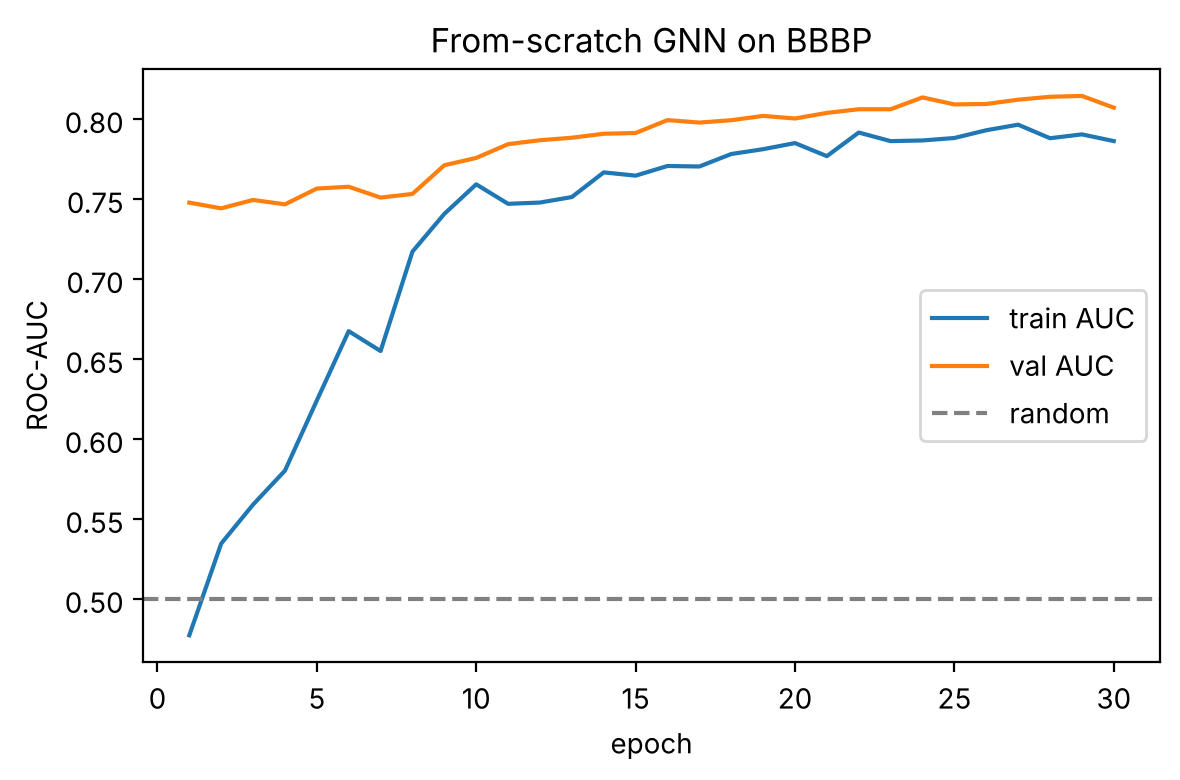

In [7]:
# restore best-validation weights, report held-out test AUC
model.load_state_dict(best_state)
_, test_auc = run_epoch(te, False)
print(f"HELD-OUT TEST ROC-AUC: {test_auc:.3f}   (0.5 = random guessing)")

plt.figure(figsize=(6,4))
plt.plot(range(1,31), hist['tr'], label='train AUC')
plt.plot(range(1,31), hist['va'], label='val AUC')
plt.axhline(0.5, ls='--', c='grey', label='random')
plt.xlabel('epoch'); plt.ylabel('ROC-AUC'); plt.title('From-scratch GNN on BBBP')
plt.legend(); plt.tight_layout(); plt.show()

## What just happened

A hand-built 3-layer GCN, trained on ~1,400 molecules, now ranks unseen drugs by BBB-penetration well above chance (ROC-AUC typically **~0.80** on this random split (NB05 pushes higher with better architectures and tuning)). It learned *purely from molecular graph structure* — no hand-crafted chemistry rules beyond the atom features.

Things worth trying (edit and re-run):
- Change depth (1 vs 5 GCN layers) → watch under-/over-smoothing from NB02 in action.
- Swap mean pooling for sum pooling in `forward`.
- Remove `weight_decay` or dropout → watch the train/val gap widen (overfitting).

## The catch

Look back at how much we wrote: normalization, block-diagonal batching, manual pooling, a bespoke loop. It works, but it's a lot of surface area for bugs, and it's slow (dense N×N matrices). **Nobody does molecular GNNs this way in practice.**

**Next — Notebook 04:** the exact same task in **PyTorch Geometric**. Every hand-written piece here maps to one library call — and you'll recognise all of them.